# Model 1 — machine failure classification

Train and evaluate a model on the [UCI AI4I 2020 Predictive Maintenance dataset](https://archive.ics.uci.edu/dataset/601/ai4i) ([DOI](https://doi.org/10.24432/C5HS5C), CC BY 4.0). The dataset is **synthetic**. Each row has a `Machine failure` label for that operating point; this is **not** a forecast of failure in the next hour or day.

**Input contract:** air temperature (K), process temperature (K), rotational speed (rpm), torque (Nm), and tool wear (min). The requested vibration input is unavailable in this dataset, so this model cannot learn from vibration. The case study's broader digital-twin, IoT update, and bottleneck requirements are outside this first model.

The notebook excludes `UDI`, `Product ID`, and the five failure-mode targets (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`) to avoid target leakage. `Type` is omitted to keep the deployment input limited to the five measured numeric fields.

In [1]:
from pathlib import Path
import json
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, fbeta_score,
                             precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, PrecisionRecallDisplay)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
if not (ROOT / 'data' / 'ai4i2020.csv').exists():
    ROOT = ROOT.parent
DATA = ROOT / 'data' / 'ai4i2020.csv'
assert DATA.exists(), f'Missing dataset: {DATA}'
FEATURES = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]',
            'Torque [Nm]', 'Tool wear [min]']
TARGET = 'Machine failure'
RANDOM_STATE = 42

## Load and inspect

Rows follow the dataset's recorded order. We keep that order for a train/validation/test split to better resemble later observations than a random split would. The CSV does not identify machines or provide timestamps, so this is still only an approximate deployment evaluation.

In [2]:
df = pd.read_csv(DATA, encoding='utf-8-sig')
assert len(df) == 10_000 and set(FEATURES + [TARGET]).issubset(df.columns)
assert not df[FEATURES + [TARGET]].isna().any().any()
assert set(df[TARGET].unique()) == {0, 1}
print('Rows, columns:', df.shape)
print('Failure rate:', f'{df[TARGET].mean():.2%}')
display(df[FEATURES + [TARGET]].head())

Rows, columns: (10000, 14)
Failure rate: 3.39%


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,298.1,308.6,1551,42.8,0,0
1,298.2,308.7,1408,46.3,3,0
2,298.1,308.5,1498,49.4,5,0
3,298.2,308.6,1433,39.5,7,0
4,298.2,308.7,1408,40.0,9,0


## Split before fitting

First 60% trains, next 20% selects the model and decision threshold, and final 20% is held out until evaluation. Failure is rare; report recall, precision, average precision, and the confusion matrix rather than accuracy alone.

In [3]:
X = df[FEATURES]
y = df[TARGET].astype(int)
X_train, X_val, X_test = X.iloc[:6000], X.iloc[6000:8000], X.iloc[8000:]
y_train, y_val, y_test = y.iloc[:6000], y.iloc[6000:8000], y.iloc[8000:]
for name, labels in [('train', y_train), ('validation', y_val), ('test', y_test)]:
    print(f'{name}: {len(labels)} rows, {labels.sum()} failures ({labels.mean():.2%})')
assert all(labels.nunique() == 2 for labels in (y_train, y_val, y_test))

train: 6000 rows, 255 failures (4.25%)
validation: 2000 rows, 45 failures (2.25%)
test: 2000 rows, 39 failures (1.95%)


## Train and select

Compare a prevalence-only baseline, a scaled balanced logistic regression, and a random forest. Choose by validation average precision (PR AUC). Then choose a threshold on that same validation segment using F2, which weights missed failures more heavily than false alerts. The untouched test segment gives the final estimate.

In [4]:
candidates = {
    'prevalence baseline': DummyClassifier(strategy='prior'),
    'logistic regression': make_pipeline(StandardScaler(), LogisticRegression(
        class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE)),
    'random forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
        class_weight='balanced_subsample', random_state=RANDOM_STATE, n_jobs=-1),
}
validation = {}
for name, estimator in candidates.items():
    estimator.fit(X_train, y_train)
    scores = estimator.predict_proba(X_val)[:, 1]
    validation[name] = {'model': estimator, 'scores': scores,
                        'average_precision': average_precision_score(y_val, scores)}
validation_table = pd.DataFrame([
    {'model': name, 'validation_average_precision': result['average_precision'],
     'validation_roc_auc': roc_auc_score(y_val, result['scores']),
     'validation_brier_score': brier_score_loss(y_val, result['scores'])}
    for name, result in validation.items()
]).sort_values('validation_average_precision', ascending=False)
display(validation_table)
selected_name = validation_table.iloc[0]['model']
selected = validation[selected_name]['model']
val_scores = validation[selected_name]['scores']
print('Selected:', selected_name)

,model,validation_average_precision,validation_roc_auc,validation_brier_score
2,random forest,0.651120,0.964939,0.013464
1,logistic regression,0.369418,0.893561,0.075715
0,prevalence baseline,0.022500,0.500000,0.022394


Selected: random forest


In [5]:
precision, recall, thresholds = precision_recall_curve(y_val, val_scores)
# Each threshold corresponds to precision/recall at the same index; the final PR point has no threshold.
f2 = 5 * precision[:-1] * recall[:-1] / np.maximum(4 * precision[:-1] + recall[:-1], 1e-12)
threshold = float(thresholds[np.argmax(f2)])
print(f'Validation F2 threshold: {threshold:.4f}')
print(f'Validation precision: {precision[np.argmax(f2)]:.3f}; recall: {recall[np.argmax(f2)]:.3f}')
assert 0 <= threshold <= 1

Validation F2 threshold: 0.2769
Validation precision: 0.486; recall: 0.756


## Held-out evaluation

These are predictions for the same-row failure label. The Brier score measures probability error; it does not establish calibration for a real production line. The threshold was selected to favor recall, but its actual alert workload is visible in the confusion matrix.

In [6]:
test_scores = selected.predict_proba(X_test)[:, 1]
test_predictions = (test_scores >= threshold).astype(int)
metrics = {
    'model': selected_name,
    'threshold': threshold,
    'test_average_precision': average_precision_score(y_test, test_scores),
    'test_roc_auc': roc_auc_score(y_test, test_scores),
    'test_brier_score': brier_score_loss(y_test, test_scores),
    'test_precision': precision_score(y_test, test_predictions, zero_division=0),
    'test_recall': recall_score(y_test, test_predictions, zero_division=0),
    'test_f2': fbeta_score(y_test, test_predictions, beta=2, zero_division=0),
}
print(json.dumps(metrics, indent=2))
print(classification_report(y_test, test_predictions, zero_division=0))
print('Confusion matrix [[TN, FP], [FN, TP]]:')
print(confusion_matrix(y_test, test_predictions))

{
  "model": "random forest",
  "threshold": 0.27686800080275537,
  "test_average_precision": 0.6292873798869674,
  "test_roc_auc": 0.9553929836948705,
  "test_brier_score": 0.012185293296469153,
  "test_precision": 0.4027777777777778,
  "test_recall": 0.7435897435897436,
  "test_f2": 0.6359649122807017
}
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      1961
           1       0.40      0.74      0.52        39

    accuracy                           0.97      2000
   macro avg       0.70      0.86      0.75      2000
weighted avg       0.98      0.97      0.98      2000

Confusion matrix [[TN, FP], [FN, TP]]:
[[1918   43]
 [  10   29]]


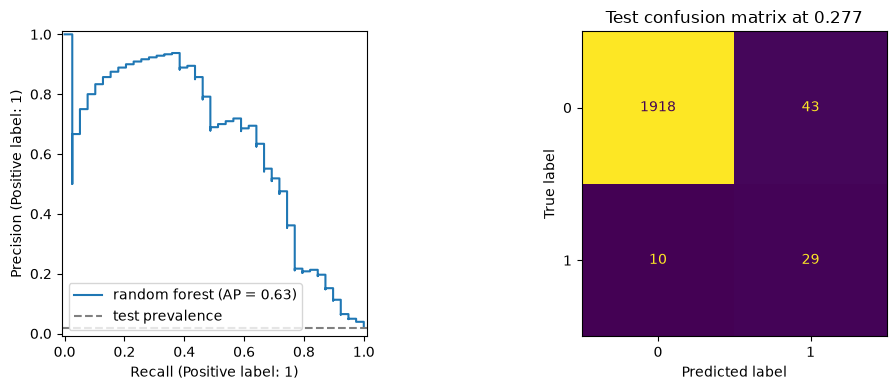

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
PrecisionRecallDisplay.from_predictions(y_test, test_scores, ax=axes[0], name=selected_name)
axes[0].axhline(y_test.mean(), color='gray', linestyle='--', label='test prevalence')
axes[0].legend()
ConfusionMatrixDisplay.from_predictions(y_test, test_predictions, ax=axes[1], colorbar=False)
axes[1].set_title(f'Test confusion matrix at {threshold:.3f}')
plt.tight_layout()
plt.show()

## Export for the future backend

The artifact stores the fitted estimator, exact feature order, and chosen threshold. The JSON file is a small interface contract for request validation and display units. Only load joblib files you trust. Score inputs using the same units and column names; a future backend should reject missing, extra, or invalid values. The returned score is a model estimate for the observed conditions, not a guaranteed future-failure probability.

In [8]:
example = X_test.iloc[[0]]
example_score = float(selected.predict_proba(example)[0, 1])
print('Example input:', example.iloc[0].to_dict())
print(f'Score: {example_score:.4f}; alert: {example_score >= threshold}')

MODEL_DIR = ROOT / 'models'
MODEL_DIR.mkdir(exist_ok=True)
artifact = {'model': selected, 'features': FEATURES, 'threshold': threshold}
joblib.dump(artifact, MODEL_DIR / 'machine_failure.joblib')
metadata = {
    'dataset': 'UCI AI4I 2020 Predictive Maintenance Dataset (CC BY 4.0)',
    'dataset_url': 'https://archive.ics.uci.edu/dataset/601/ai4i',
    'target': TARGET,
    'features': FEATURES,
    'threshold': threshold,
    'selected_model': selected_name,
    'test_metrics': metrics,
    'interpretation': 'Same-row machine failure classification on synthetic data; no vibration or future horizon.',
}
(MODEL_DIR / 'machine_failure_metadata.json').write_text(json.dumps(metadata, indent=2) + '\n')
print('Saved:', MODEL_DIR / 'machine_failure.joblib')
print('Saved:', MODEL_DIR / 'machine_failure_metadata.json')

Example input: {'Air temperature [K]': 300.8, 'Process temperature [K]': 312.0, 'Rotational speed [rpm]': 1443.0, 'Torque [Nm]': 53.3, 'Tool wear [min]': 151.0}
Score: 0.0793; alert: False


Saved: /Users/harshitgoswami/UNI/AAI/backend/models/machine_failure.joblib
Saved: /Users/harshitgoswami/UNI/AAI/backend/models/machine_failure_metadata.json


## Next data needed for the digital twin

- Collect real, timestamped sensor observations with machine IDs, both temperatures, rotational speed, torque, tool wear, and a measured vibration signal with units and sampling frequency.
- Define an alert horizon (for example, failure within 24 hours), record failure and maintenance timestamps, and rebuild labels accordingly. Split by time and machine to test generalization.
- Update the twin as observations arrive, retain sensor timestamps and missing-data status, and show the score together with model version, threshold, and observed validation limits. Reassess calibration and alert load on real data before using alerts operationally.